In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Final theta:
[[4.21509616]
 [2.77011339]]


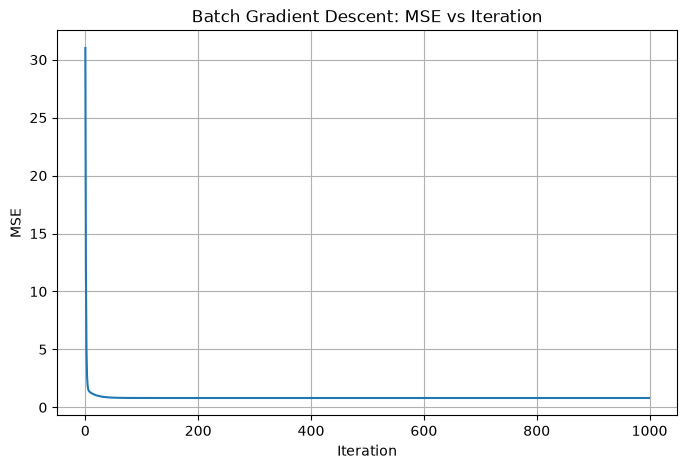

In [2]:
np.random.seed(42)

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

# Add bias column
X_b = np.c_[np.ones((100, 1)), X]

# Random initialization of theta
theta = np.random.randn(2, 1)

learning_rate = 0.1
n_iterations = 1000

m = len(X)

mse_history = []

for iteration in range(n_iterations):

    # Predictions
    y_pred = X_b @ theta

    # MSE
    mse = np.mean((y_pred - y) ** 2)
    mse_history.append(mse)

    # Gradient
    gradients = (2 / m) * X_b.T @ (y_pred - y)

    # Update theta
    theta = theta - learning_rate * gradients

print("Final theta:")
print(theta)

# Plot MSE
plt.figure(figsize=(8, 5))
plt.plot(mse_history)
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Batch Gradient Descent: MSE vs Iteration")
plt.grid()
plt.show()

In [3]:
# Stochastic Gradient Descent

theta_sgd = np.random.randn(2, 1)

t0 = 5
t1 = 50
n_epochs = 50

sgd_mse_history = []
update_count_sgd = 0

for epoch in range(n_epochs):

    # Shuffle data
    shuffled_indices = np.random.permutation(m)
    X_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]

    for i in range(m):

        xi = X_shuffled[i:i+1]
        yi = y_shuffled[i:i+1]

        # Prediction for one instance
        y_pred = xi @ theta_sgd

        # Gradient for one instance
        gradients = 2 * xi.T @ (y_pred - yi)

        # Learning rate
        eta = t0 / (epoch * m + i + t1)

        # Update
        theta_sgd = theta_sgd - eta * gradients

        update_count_sgd += 1

    # MSE after each epoch
    predictions = X_b @ theta_sgd
    mse = np.mean((predictions - y) ** 2)

    sgd_mse_history.append(mse)

print("SGD final theta:")
print(theta_sgd)

print("SGD parameter updates:", update_count_sgd)

SGD final theta:
[[4.21378815]
 [2.76962859]]
SGD parameter updates: 5000


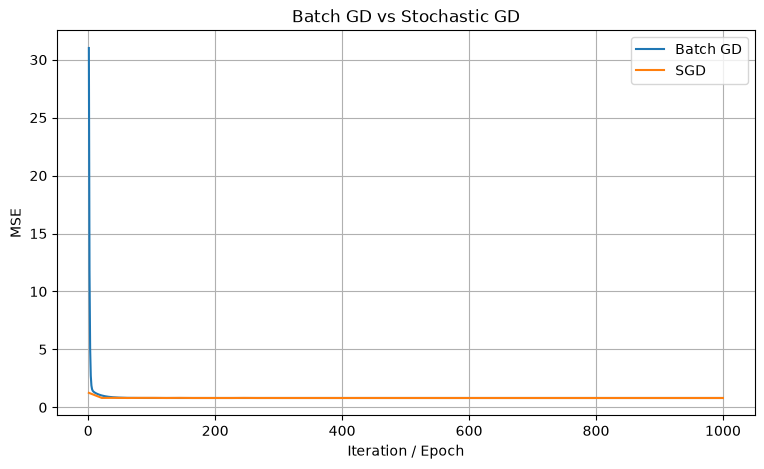

In [4]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(mse_history) + 1),
    mse_history,
    label="Batch GD"
)

plt.plot(
    np.linspace(1, len(mse_history), len(sgd_mse_history)),
    sgd_mse_history,
    label="SGD"
)

plt.xlabel("Iteration / Epoch")
plt.ylabel("MSE")
plt.title("Batch GD vs Stochastic GD")
plt.legend()
plt.grid()
plt.show()

In [5]:
# Mini-Batch Gradient Descent

batch_size = 20
n_epochs = 50
learning_rate = 0.1

theta_mini = np.random.randn(2, 1)

mini_mse_history = []
epoch_reached = None

for epoch in range(n_epochs):

    # Shuffle
    shuffled_indices = np.random.permutation(m)
    X_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]

    for start in range(0, m, batch_size):

        end = start + batch_size

        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        # Prediction
        y_pred = X_batch @ theta_mini

        # Gradient
        gradients = (2 / len(X_batch)) * \
                    X_batch.T @ (y_pred - y_batch)

        # Update
        theta_mini = theta_mini - learning_rate * gradients

    # MSE after epoch
    predictions = X_b @ theta_mini
    mse = np.mean((predictions - y) ** 2)

    mini_mse_history.append(mse)

    if epoch_reached is None and mse < 1.0:
        epoch_reached = epoch + 1

print("Mini-Batch final theta:")
print(theta_mini)

print("Epoch reaching MSE < 1:", epoch_reached)

Mini-Batch final theta:
[[4.20479835]
 [2.76312115]]
Epoch reaching MSE < 1: 1


In [6]:
# Epoch at which Batch GD reaches MSE < 1
batch_epoch = None

for i, mse in enumerate(mse_history):
    if mse < 1:
        batch_epoch = i + 1
        break

# SGD
sgd_epoch = None

for i, mse in enumerate(sgd_mse_history):
    if mse < 1:
        sgd_epoch = i + 1
        break

# Mini-batch
mini_epoch = None

for i, mse in enumerate(mini_mse_history):
    if mse < 1:
        mini_epoch = i + 1
        break

print("\nFinal theta values")
print("-----------------------------")
print("Batch GD      :", theta.ravel())
print("SGD           :", theta_sgd.ravel())
print("Mini-batch GD :", theta_mini.ravel())

print("\nEpoch reaching MSE < 1")
print("-----------------------------")
print("Batch GD      :", batch_epoch)
print("SGD           :", sgd_epoch)
print("Mini-batch GD :", mini_epoch)


Final theta values
-----------------------------
Batch GD      : [4.21509616 2.77011339]
SGD           : [4.21378815 2.76962859]
Mini-batch GD : [4.20479835 2.76312115]

Epoch reaching MSE < 1
-----------------------------
Batch GD      : 23
SGD           : 2
Mini-batch GD : 1


In [7]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

np.random.seed(42)

X = 6 * np.random.rand(100, 1) - 3

y = (
    0.5 * X**2
    + X
    + 2
    + np.random.randn(*X.shape)
)

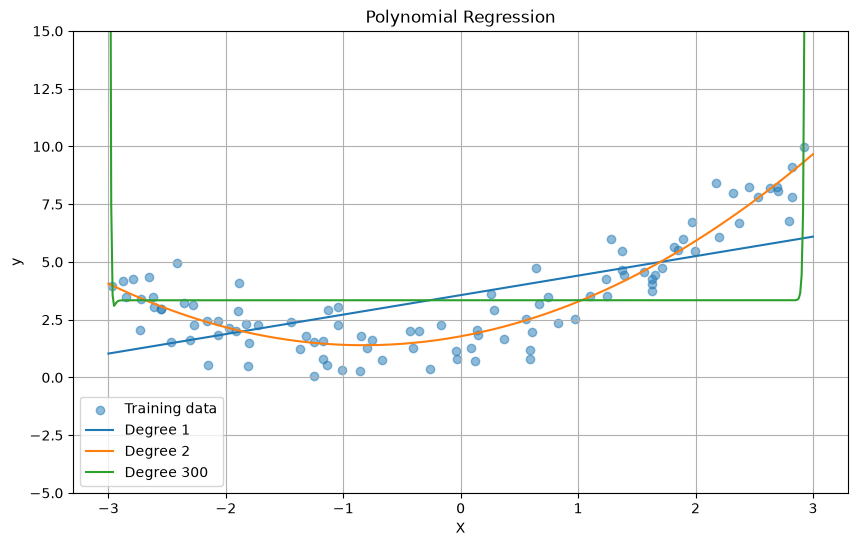

In [8]:
degrees = [1, 2, 300]

X_plot = np.linspace(-3, 3, 500).reshape(-1, 1)

plt.figure(figsize=(10, 6))

plt.scatter(X, y, alpha=0.5, label="Training data")

for degree in degrees:

    poly = PolynomialFeatures(degree=degree)

    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    X_plot_poly = poly.transform(X_plot)

    y_plot = model.predict(X_plot_poly)

    plt.plot(
        X_plot,
        y_plot,
        label=f"Degree {degree}"
    )

plt.xlabel("X")
plt.ylabel("y")
plt.title("Polynomial Regression")
plt.legend()
plt.ylim(-5, 15)
plt.grid()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

def plot_learning_curves(model, X, y):

    X_train, X_val, y_train, y_val = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )

    train_errors = []
    val_errors = []

    for m in range(1, len(X_train)):

        model.fit(X_train[:m], y_train[:m])

        y_train_predict = model.predict(X_train[:m])
        y_val_predict = model.predict(X_val)

        train_rmse = np.sqrt(
            mean_squared_error(
                y_train[:m],
                y_train_predict
            )
        )

        val_rmse = np.sqrt(
            mean_squared_error(
                y_val,
                y_val_predict
            )
        )

        train_errors.append(train_rmse)
        val_errors.append(val_rmse)

    return train_errors, val_errors

In [19]:
poly1 = PolynomialFeatures(degree=1)

model1 = LinearRegression()

X_poly1 = poly1.fit_transform(X)

train_errors1, val_errors1 = plot_learning_curves(
    model1,
    X_poly1,
    y
)

In [20]:
poly300 = PolynomialFeatures(degree=300)

model300 = LinearRegression()

X_poly300 = poly300.fit_transform(X)

train_errors300, val_errors300 = plot_learning_curves(
    model300,
    X_poly300,
    y
)

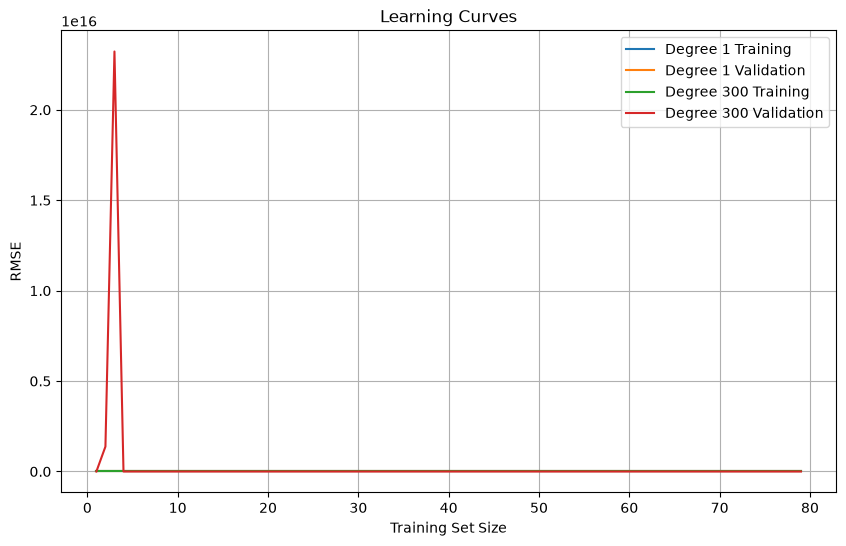

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(train_errors1) + 1),
    train_errors1,
    label="Degree 1 Training"
)

plt.plot(
    range(1, len(val_errors1) + 1),
    val_errors1,
    label="Degree 1 Validation"
)

plt.plot(
    range(1, len(train_errors300) + 1),
    train_errors300,
    label="Degree 300 Training"
)

plt.plot(
    range(1, len(val_errors300) + 1),
    val_errors300,
    label="Degree 300 Validation"
)

plt.xlabel("Training Set Size")
plt.ylabel("RMSE")
plt.title("Learning Curves")
plt.legend()
plt.grid()
plt.show()

In [24]:
df = pd.read_csv(
    "winequality-red.csv"
)

print(df.head())
print(df.shape)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [25]:
X = df.drop("quality", axis=1)
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
alphas = [0.001, 0.01, 0.1, 1, 10]

In [27]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error

results = []

for alpha in alphas:

    models = {
        "Ridge": Ridge(alpha=alpha),
        "Lasso": Lasso(alpha=alpha, max_iter=10000),
        "ElasticNet": ElasticNet(
            alpha=alpha,
            l1_ratio=0.5,
            max_iter=10000
        )
    }

    for name, model in models.items():

        model.fit(
            X_train_scaled,
            y_train
        )

        predictions = model.predict(
            X_test_scaled
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                predictions
            )
        )

        results.append({
            "Model": name,
            "Alpha": alpha,
            "Test RMSE": rmse
        })

results_df = pd.DataFrame(results)

print(results_df)

         Model   Alpha  Test RMSE
0        Ridge   0.001   0.624520
1        Lasso   0.001   0.624881
2   ElasticNet   0.001   0.624701
3        Ridge   0.010   0.624520
4        Lasso   0.010   0.626909
5   ElasticNet   0.010   0.626290
6        Ridge   0.100   0.624521
7        Lasso   0.100   0.662740
8   ElasticNet   0.100   0.644144
9        Ridge   1.000   0.624530
10       Lasso   1.000   0.810654
11  ElasticNet   1.000   0.810654
12       Ridge  10.000   0.624641
13       Lasso  10.000   0.810654
14  ElasticNet  10.000   0.810654


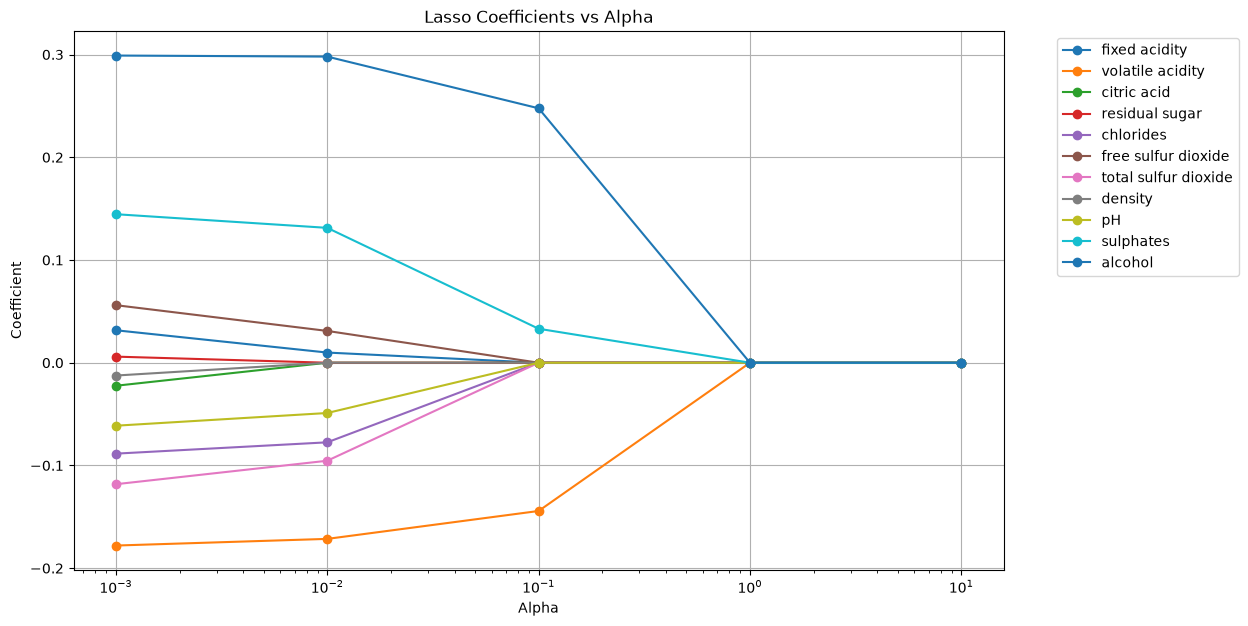

In [28]:
lasso_coefficients = {}

for alpha in alphas:

    lasso = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    lasso.fit(
        X_train_scaled,
        y_train
    )

    lasso_coefficients[alpha] = lasso.coef_

# Convert to array
coef_matrix = np.array(
    [lasso_coefficients[a] for a in alphas]
)

plt.figure(figsize=(12, 7))

for i, feature in enumerate(X.columns):

    plt.plot(
        alphas,
        coef_matrix[:, i],
        marker="o",
        label=feature
    )

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.title("Lasso Coefficients vs Alpha")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid()
plt.show()

In [29]:
zero_first = None

for j, feature in enumerate(X.columns):

    for i, alpha in enumerate(alphas):

        if np.isclose(coef_matrix[i, j], 0):

            zero_first = feature
            first_alpha = alpha
            break

    if zero_first is not None:
        break

print(
    "Feature reaching zero first:",
    zero_first
)

print(
    "Alpha:",
    first_alpha
)

Feature reaching zero first: fixed acidity
Alpha: 0.1


In [30]:
df["good"] = (df["quality"] >= 7).astype(int)

print(df["good"].value_counts())

good
0    1382
1     217
Name: count, dtype: int64


In [31]:
X = df.drop(
    ["quality", "good"],
    axis=1
)

y = df["good"]

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [33]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000
)

log_model.fit(
    X_train_scaled,
    y_train
)

y_pred = log_model.predict(
    X_test_scaled
)

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.89375
Precision: 0.6956521739130435
Recall   : 0.37209302325581395
F1-score : 0.48484848484848486


In [37]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data[:, [2, 3]]
y = iris.target
    
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [39]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000
)

model.fit(X, y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [40]:
x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5

y_min = X[:, 1].min() - 0.5
y_max = X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

In [41]:
grid = np.c_[
    xx.ravel(),
    yy.ravel()
]

In [42]:
Z = model.predict(grid)

Z = Z.reshape(xx.shape)

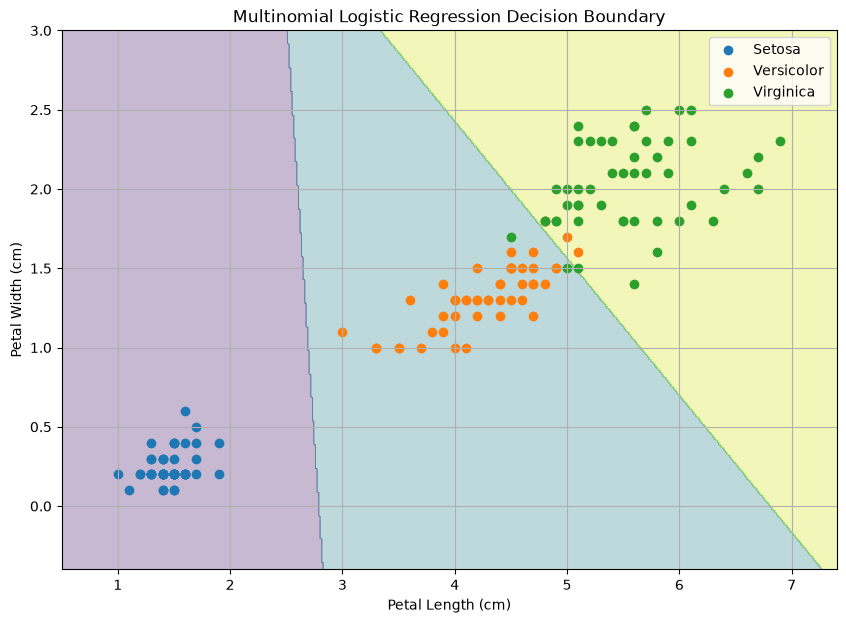

In [43]:
plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3
)

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Setosa"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Versicolor"
)

plt.scatter(
    X[y == 2, 0],
    X[y == 2, 1],
    label="Virginica"
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title(
    "Multinomial Logistic Regression Decision Boundary"
)

plt.legend()
plt.grid()
plt.show()